# Convolutional Neural Networks

## 1 Lead-in

### 1.1 problems

Former models 忽略了图片的 Spacial structure，解决方法就是引入新的operators: convolution

> question: 那么拓展出来的文字cnn（似乎没有空间结构）呢？

- 忽略输入元素之间的局部邻近关系；
- 每个位置使用不同参数，参数量很大；
- 同一个模式移动到其他位置后，需要重新学习。

### 1.2 Components:

- Convolutional layer
- Pooling layer
- Fully-connected layer(already learned)
- Normalization
- Activation function(already learned)

### 1.3 Convolutional layer

#### 1.3.1 Structure

![structure](convolution_layer_structure.png)

**input:**

- N:样本数
- $C_{in}$：输入通道数
- $H，W$：输入图片分辨率

**filter:**

- $C_{out}$：输出通道数，也是filter的个数（是一个超参，越大模型越复杂越难算，可以从小到达调整）
- $C_{in}$：filter通道数 = 输入通道数
- $K$：filter大小，即filter的分辨率

**output:**

- $N$：样本数
- $C_{out}$：输出通道数，也是filter的个数
- $H\prime，W\prime$：输出图片分辨率

#### 1.3.2 Meaning

##### 1.3.2.1 如何理解输出

以6\*28\*28的输出为例，

- 28\*28 at each point a 6-dim vector(feature vector)，
- 6\*28\*28 picture

##### 1.3.2.2 convolution操作本质

同一组权重，滑到哪里，就对哪里的局部数据做点积（即所有相应位置的相乘再相加，而两个同形状张量的内积，等价于把它们都展开成长度为 75 的向量，再做点积）

##### 1.3.2.3 What do convolutional layers learn?

局部特征：边缘、线条等等

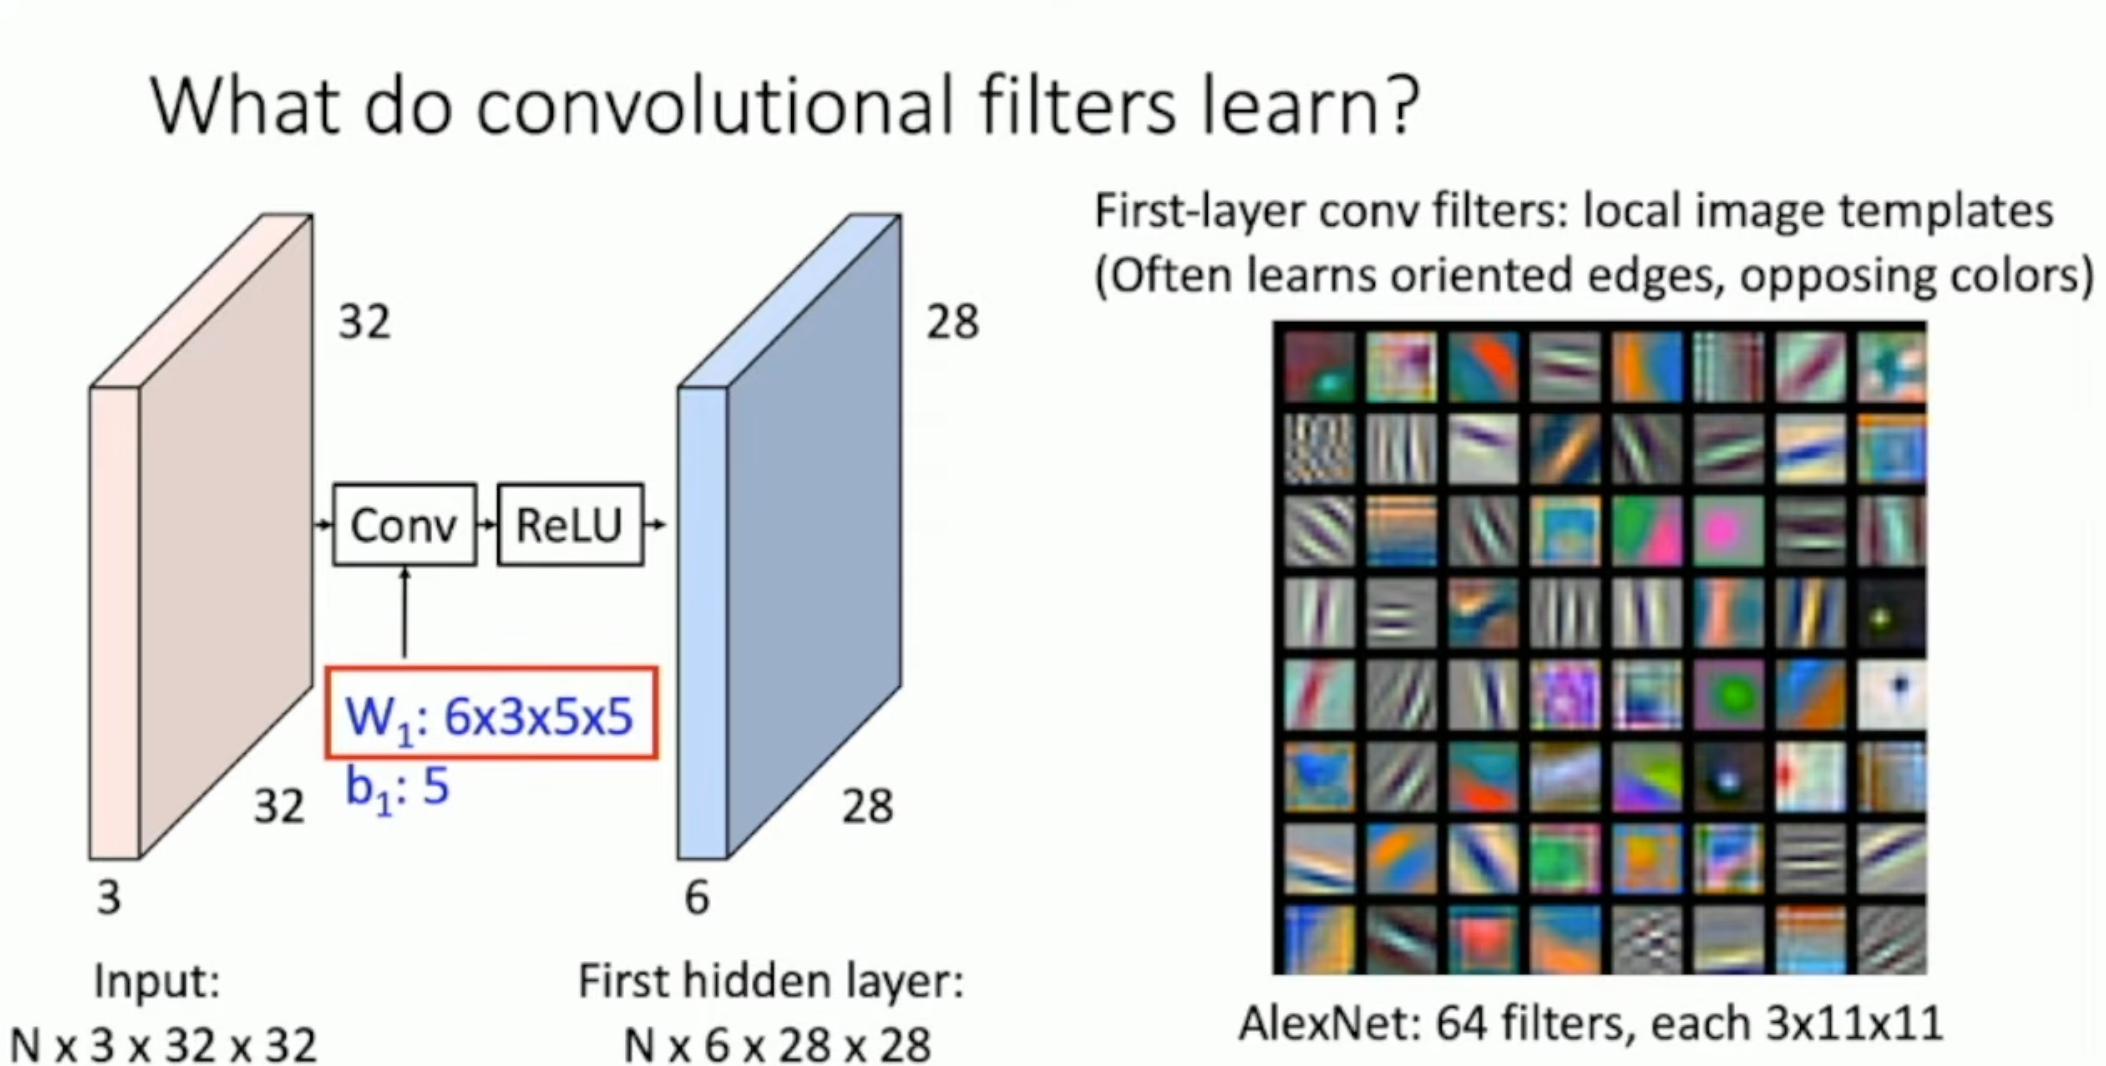

#### 1.3.3 Compute

##### 1.3.3.1 Padding

**problem:** feature maps shrink with each layer, and finally we have nothing.

**solution:** add padding to the input image.

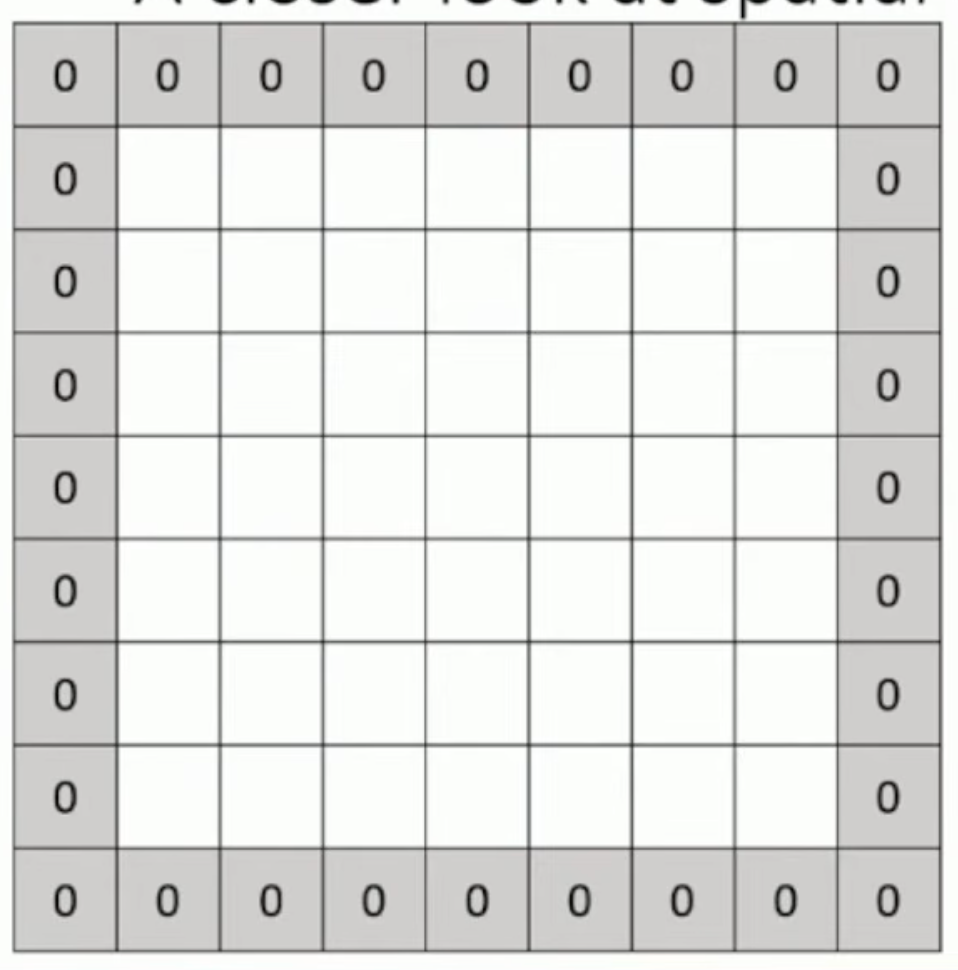

##### 1.3.3.2 stride

**problem:** 对于大型图片（eg. 224x224），需要非常多的卷积核，增加计算难度

**solution:** 多隔几个再放卷积核，比如stride=2

##### 1.3.3.3 算输出

- Input: W
- Filter: K
- Stride: S
- Padding: P

输出的尺寸为：

$$
\begin{aligned}
&(N, C_{out}, H_{out}, W_{out})\\
&\quad = \left(
N,\ C_{out},\
\frac{H_{in} + 2 \times P - K}{S} + 1,\
\frac{W_{in} + 2 \times P - K}{S} + 1
\right)
\end{aligned}
$$

**Number of learnable parameters:**

$$
C_{out} \times C_{in} \times K \times K
$$

#### 1.3.4 other types of convolution

##### 1.3.4.1 1\*1 convolution
1\*1卷积相当于在每个空间位置上，使用同一个全连接层。
| $1\times1$ 卷积 | MLP |
|---|---|
| 每次处理一个空间位置 | 同时处理整个输入 |
| 混合当前位置的通道 | 混合所有位置和通道 |
| 所有位置共享权重 | 不同输入位置通常有不同权重 |
| 保留 $H\times W$ 的 结构 | 通常输出一个向量 |
| 参数量与 $H,W$ 无关 | 参数量通常随$H,W$ 增长 |

#### 1.3.4.2

1D(text), 2D, 3D convolution

## 2 Pooling Layer

A way to down sample the image is to use a pooling layer.

> downsample: 降低数据的分辨率

CNN 常见的下采样方式有：

- 最大池化：每个小区域取最大值。
- 平均池化：每个小区域取平均值。
- 步长大于 1 的卷积：例如 stride=2，卷积核每次移动两格，产生更少的输出位置。

poolilng layer可以理解为一个stride=kernel_size的卷积层，

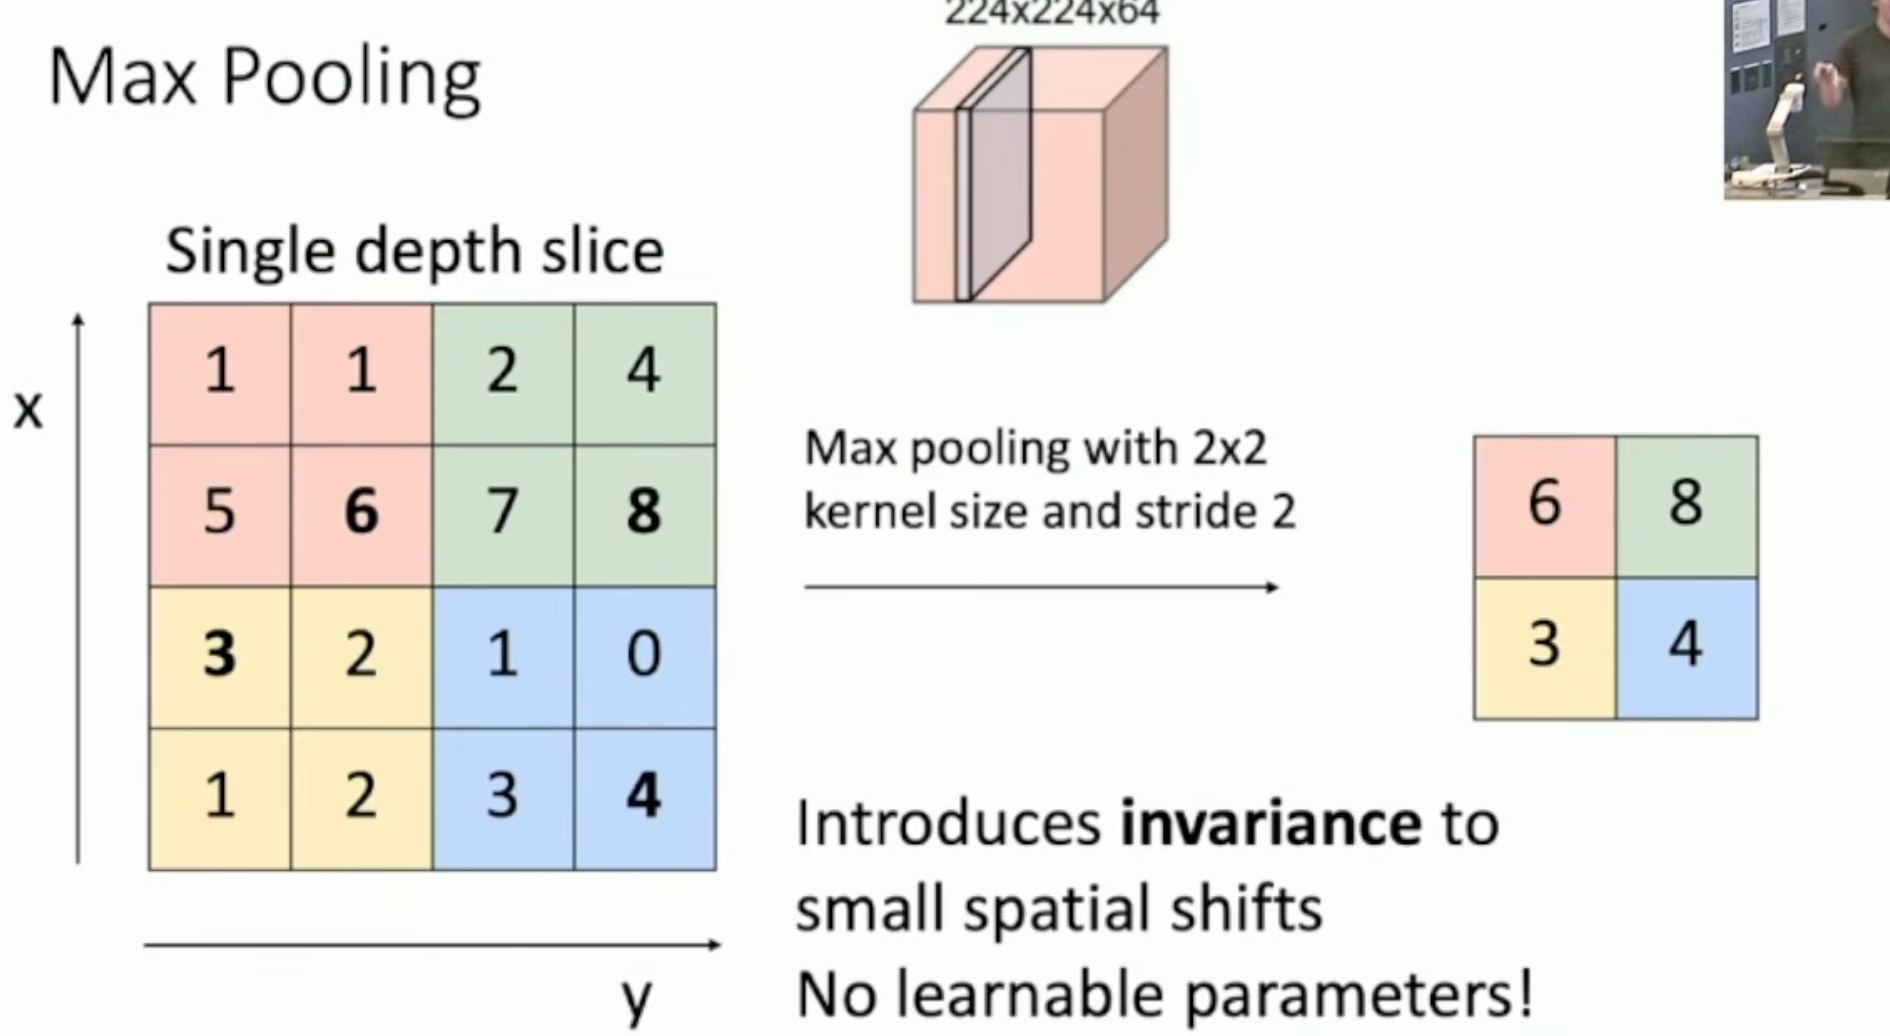

**参数：**

- poopling_function: 池化的函数，如max_pooling, avg_pooling
- pool_size: 池化的大小，如2x2

**注：**

pooling_layer没有learnable parameters。

## 3 Normalization

深度网络往往不好优化，所以需要normalization，常见的如batch normalization, layer normalization, group normalization。

### 3.1 Batch Normalization for MLP

对样本数做平均

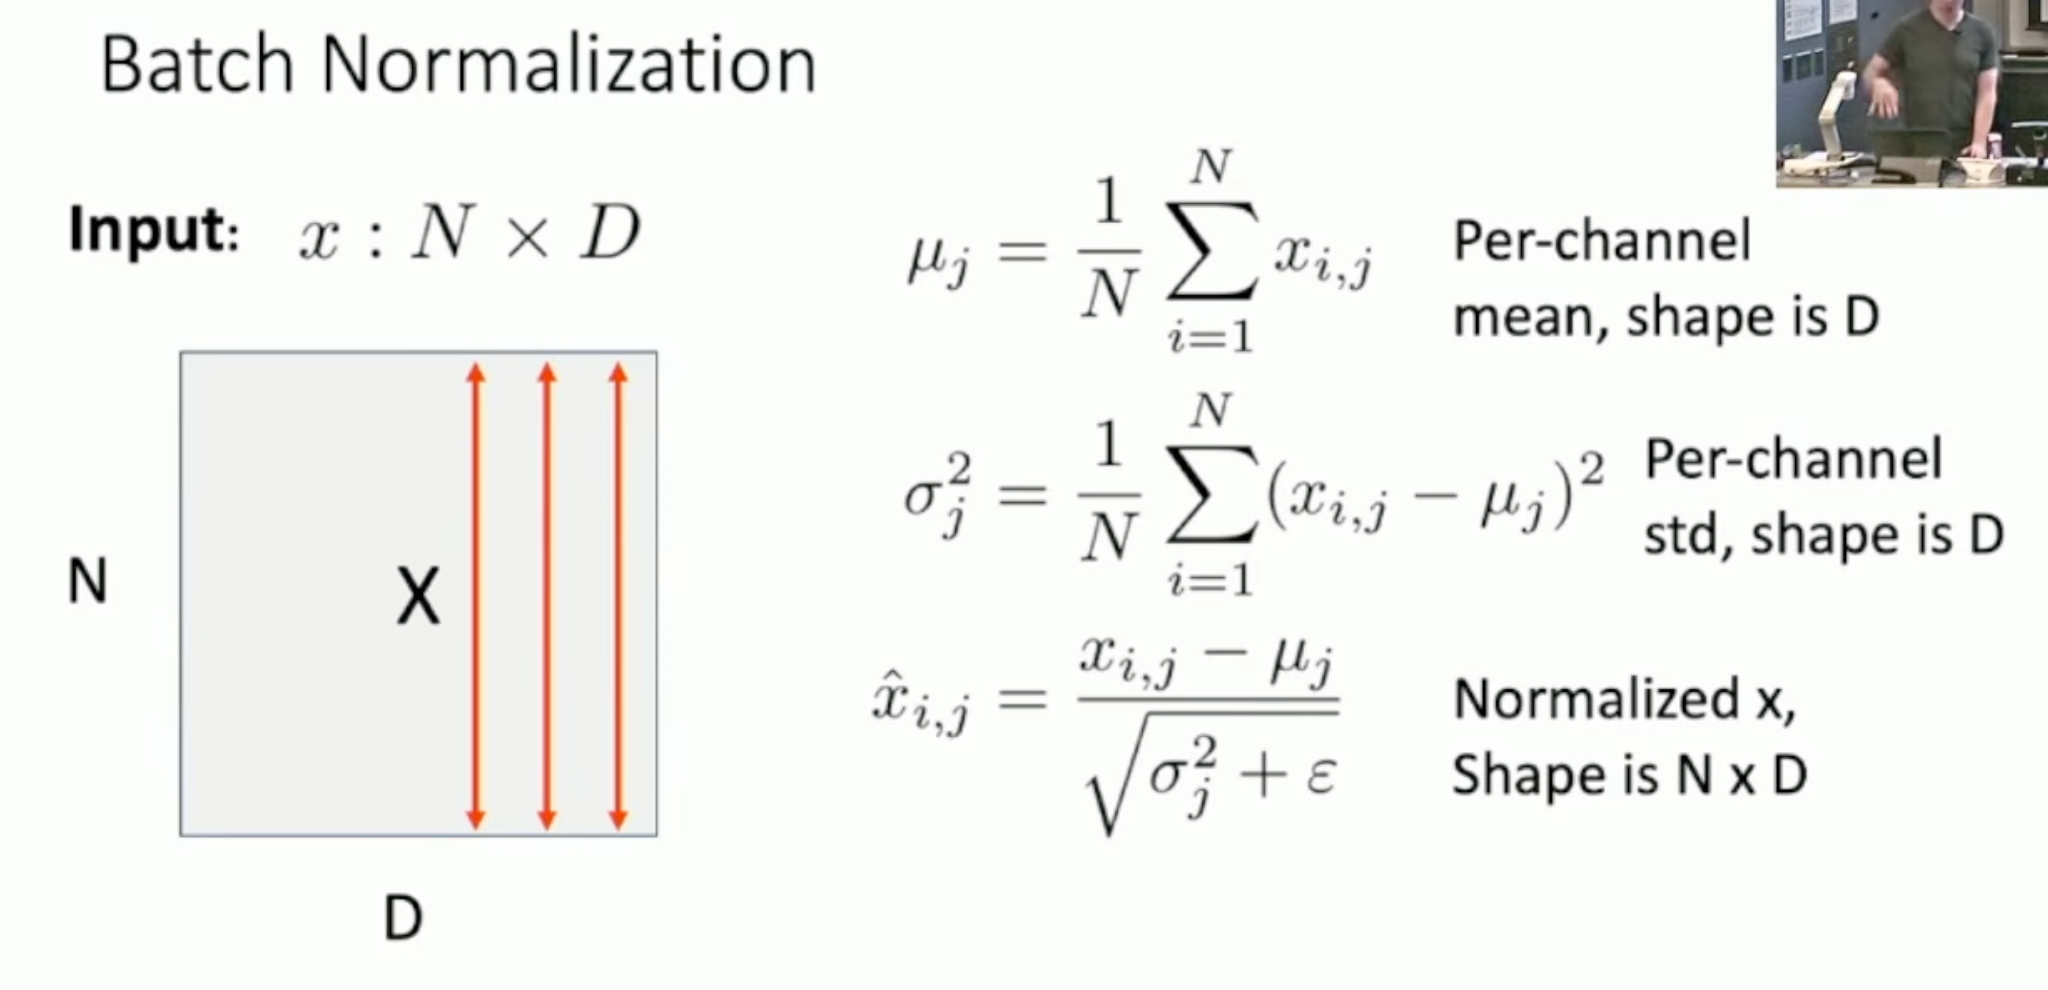

**problem:** 只有经验平均，但此平均法在test时不好用（因为test我们经常只有一个样本）

**solution:** test采用移动平均法, train采用经验平均法。

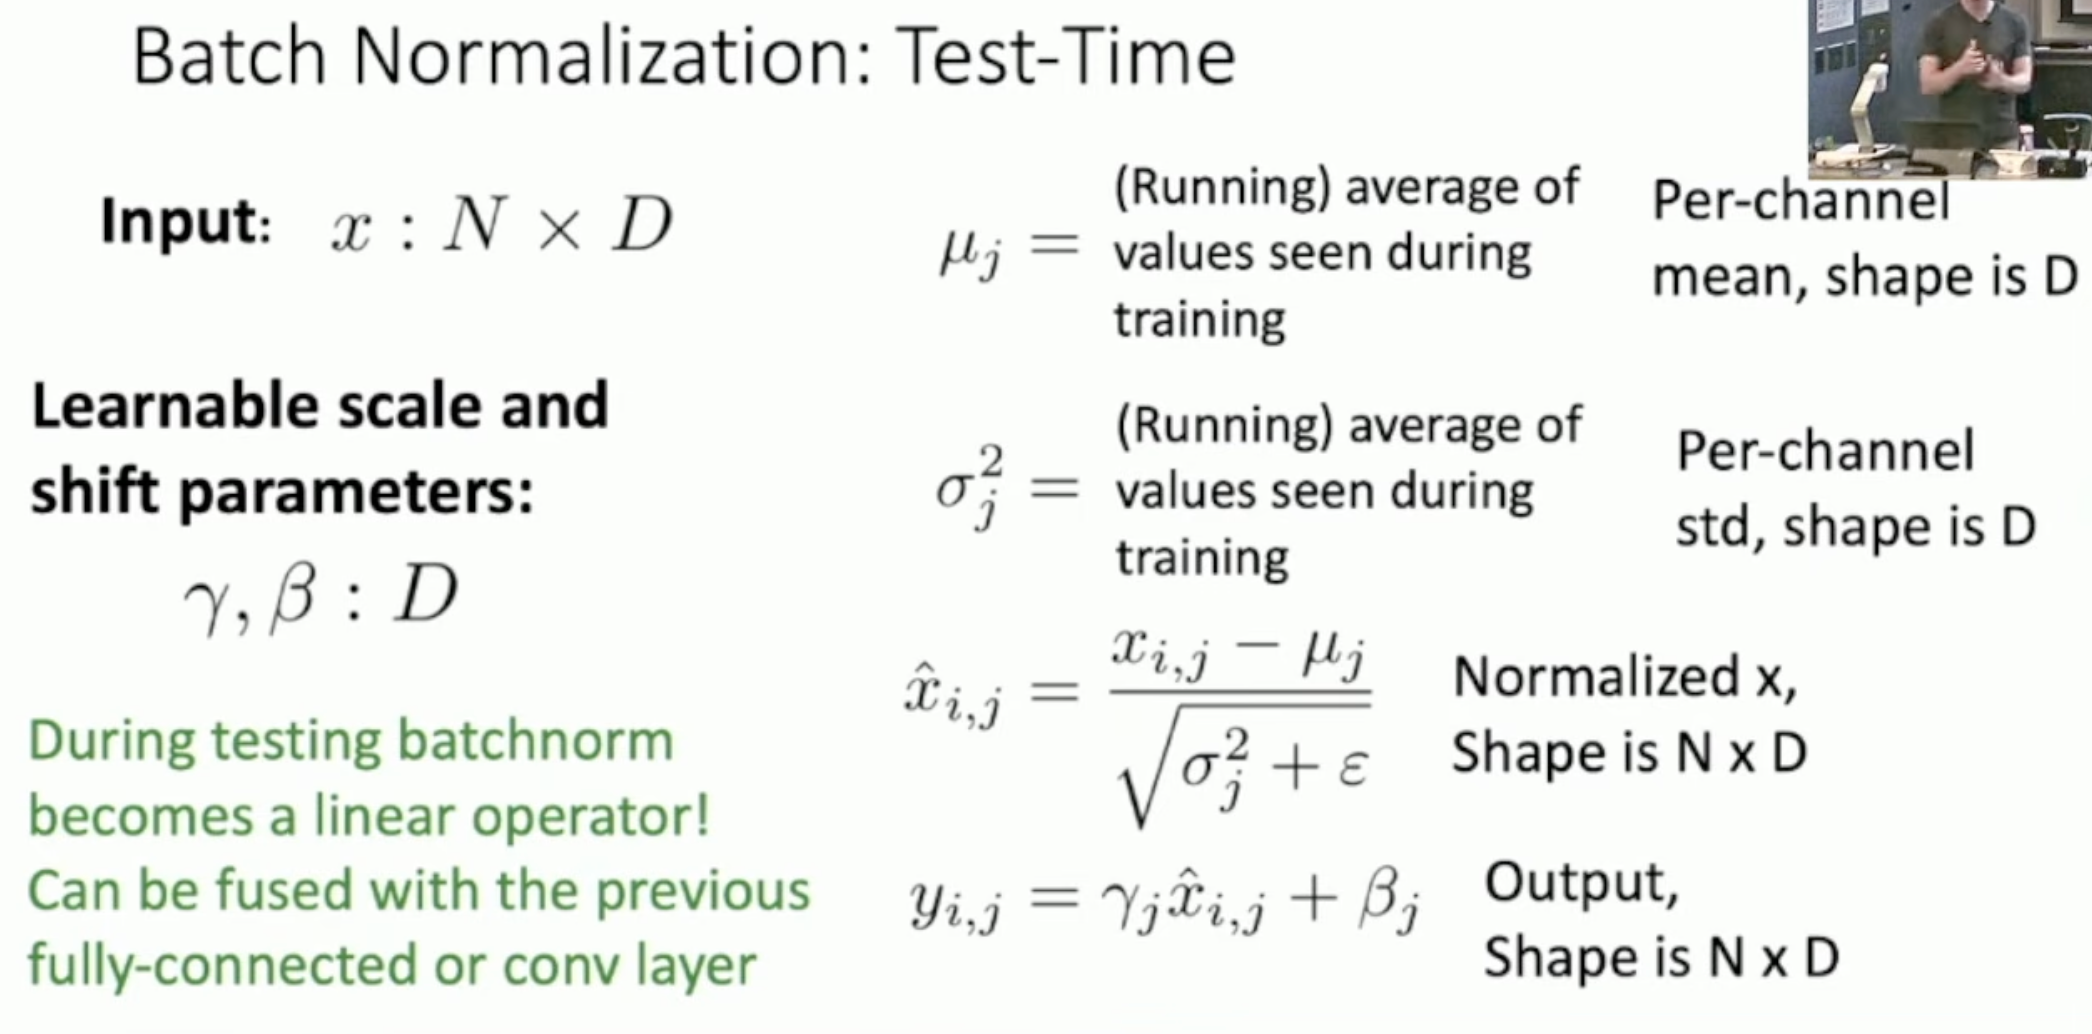

值得注意的是test 和 train 采用不同平均法非常容易出错，一定要记得。

### 3.2 Batch Normalization for CNN

和MLP一样，对样本数做平均

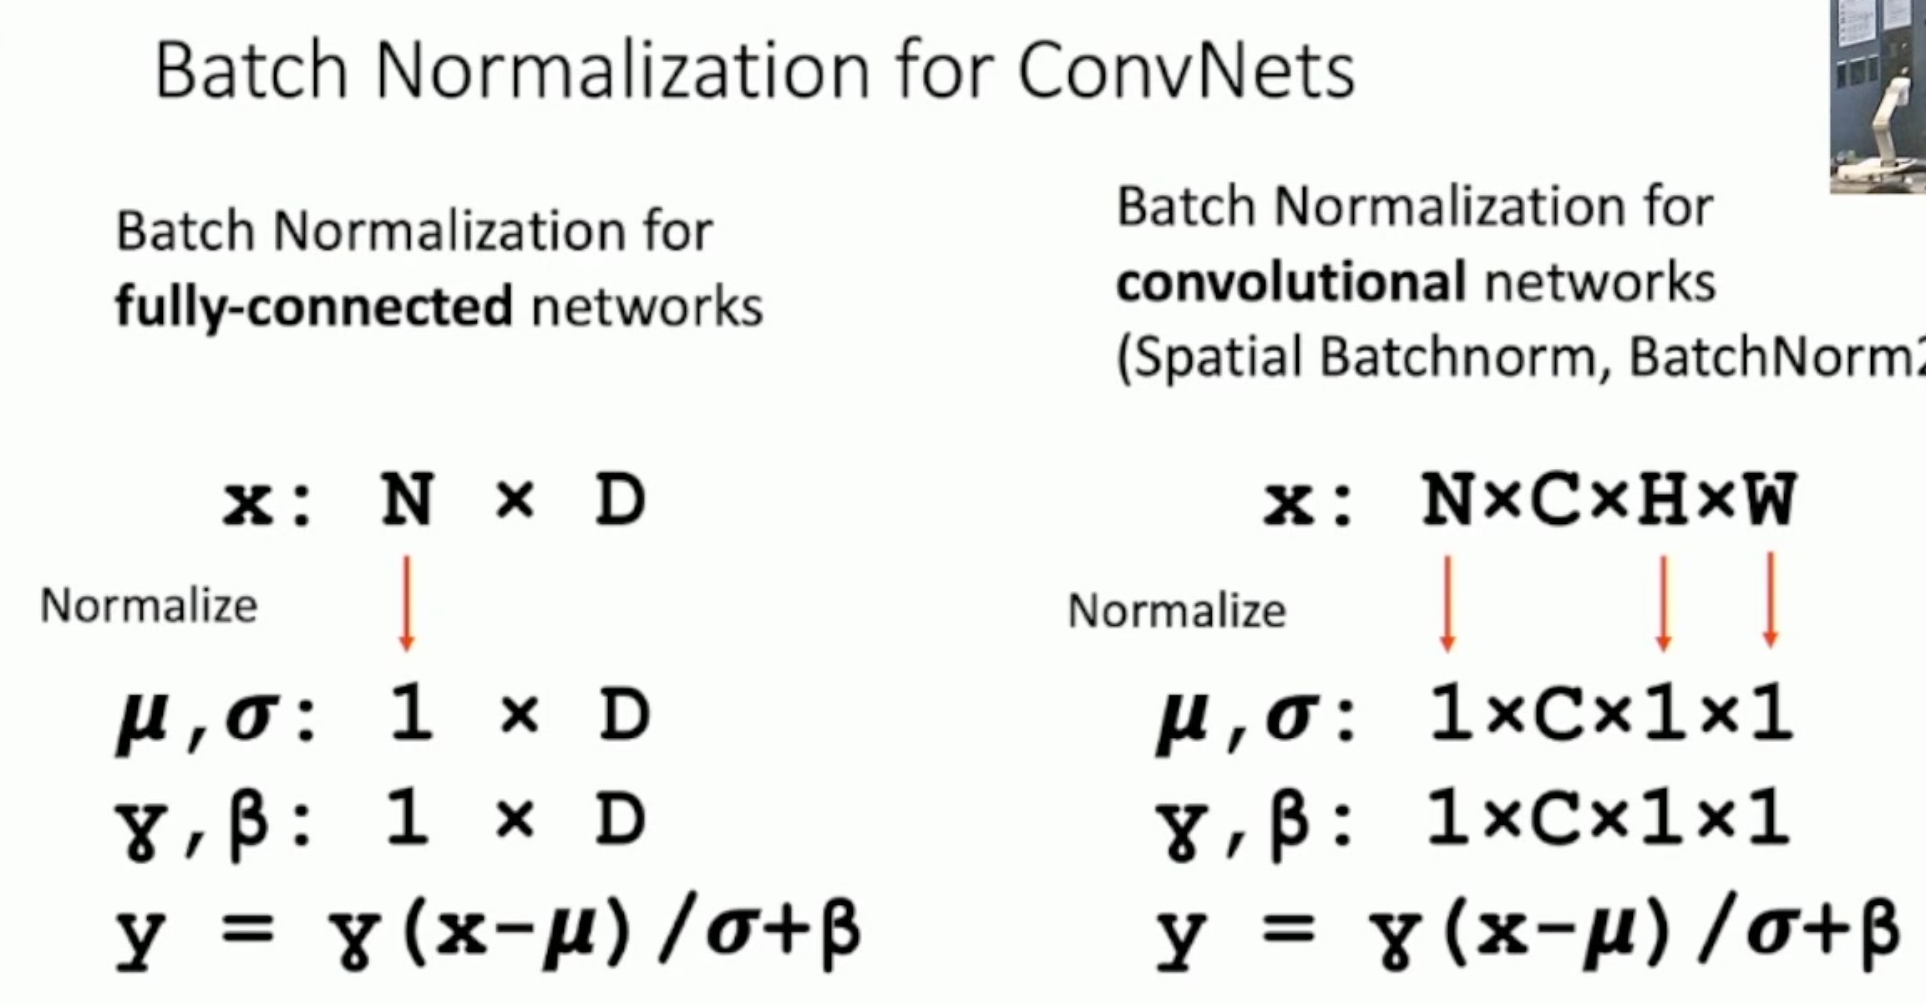

### 3.3 Other Normalizations

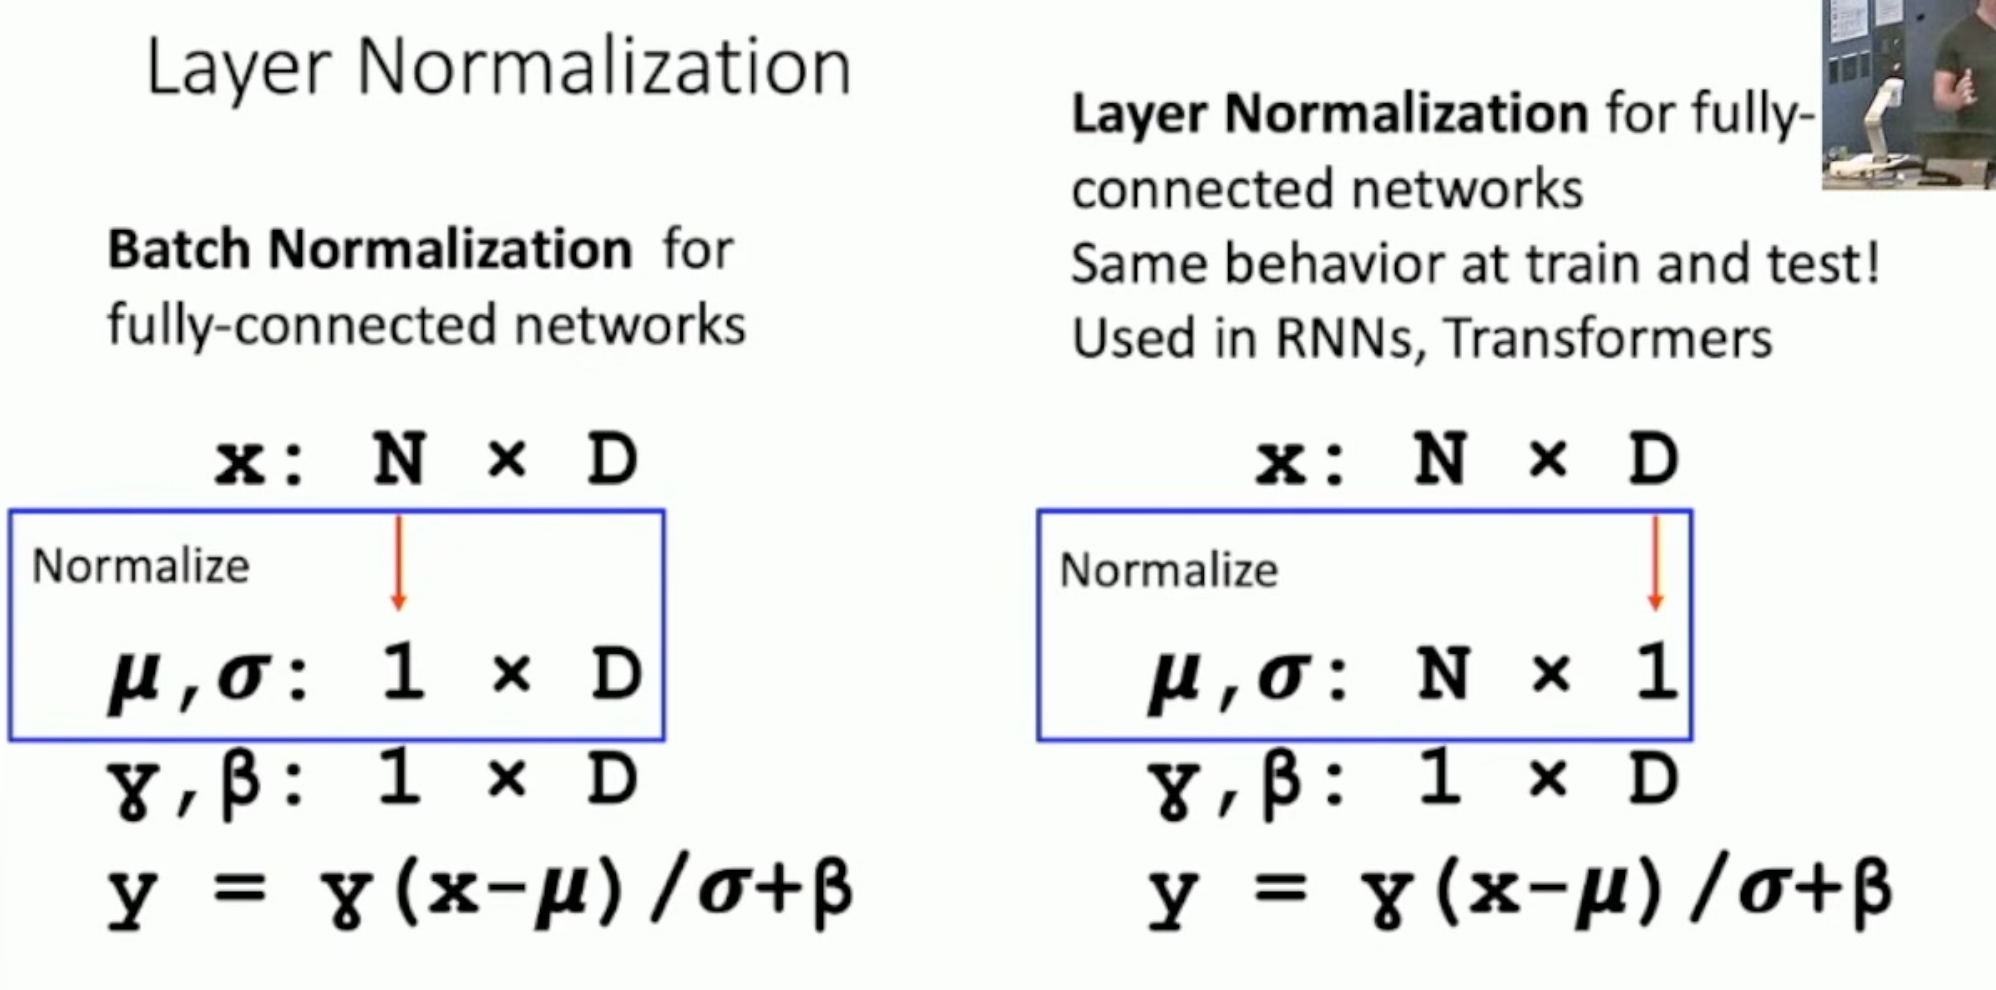

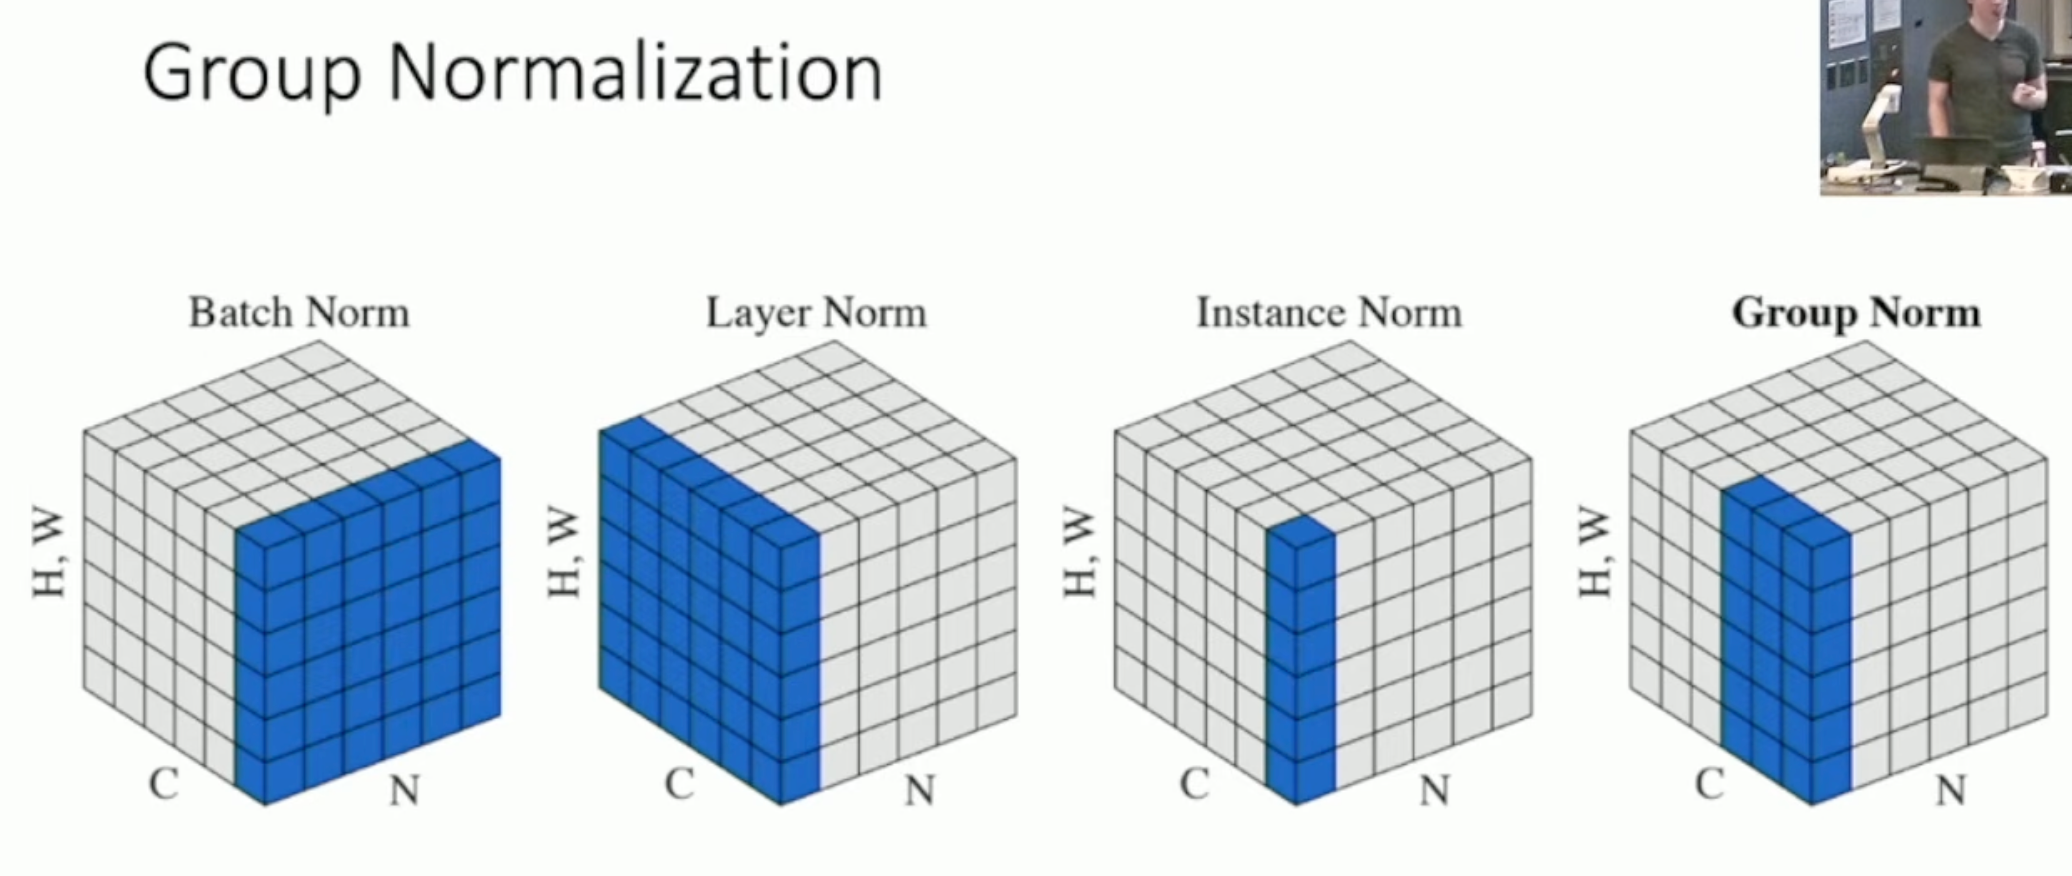